# Respuesta MT y una decisión QC

**Nivel 1 — Fundamentos**  
**Prerrequisitos:** nociones de Python; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` es requerido por el operador directo MT.

## Datos

Registro medido solo QC y artefacto sintético de calibración separado; no mezcle estas clases de evidencia.

## Método

Clear Lake `cl061` es un conjunto medido de terreno con 42 frecuencias y verdad del subsuelo desconocida. Su recibo falla la prueba necesaria de consistencia tensorial 1D; permanece **solo para QC** y no debe ajustarse con la inversa estratificada. Esta lección aplica directamente al tensor y las incertidumbres marginales versionadas los diagnósticos implementados `mt_field_qc.tensor_gate` y `phase_tensor_diagnostic`. También inspecciona el tipper suministrado, evidencia auxiliar que nunca se usa como entrada del solver 1D.

Se conserva la rotación EDI en el marco recibido (`rotation_action: none`); no se intenta una rerrotación sin covarianza. El módulo comprueba que la distancia geométrica a un tensor 1D ideal sea invariante ante un giro de 90°, propiedad diagnóstica y no reprocesamiento de esta estación. La varianza del tipper está explícitamente sin interpretar en el recibo; por ello se grafican solo magnitudes de componentes y frecuencias faltantes. No se calculan residuos normalizados ni barras de error del tipper.

Con `exp(+iωt)`, `Z=E/H` está en Ω, la resistividad aparente `ρₐ=|Z|²/(μ₀ω)` en Ω·m, la fase en grados y el período `T=1/f` en segundos. La prueba es un nulo necesario de consistencia, no una demostración de dimensionalidad. Un fallo no se corrige ajustando una inversión 1D.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
# Aplicar diagnósticos QC implementados al tensor medido; no ajustar cl061.
import json, sys
from pathlib import Path
import numpy as np
from importlib.metadata import version
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
sys.path.insert(0,str(root/"data-pipeline"))
from mt_field_qc import tensor_gate, phase_tensor_diagnostic
case=json.loads((root/"data/derived/v2/edi/clear-lake-cl061-screen.json").read_text(encoding="utf-8"))
f=np.asarray(case["frequencies_hz"],float); period=1/f
z=np.asarray(case["tensor"]["real"])+1j*np.asarray(case["tensor"]["imag"])
sigma=np.asarray(case["tensor"]["sigma"],float)
gate=tensor_gate(z,sigma**2)  # El recibo guarda SD marginal; la función QC recibe varianza.
phase_qc=phase_tensor_diagnostic(z); tip=case["metadata"]["tipper"]
print("Versiones:",{name:version(name) for name in ("numpy","matplotlib","scipy")})
print("Fuente medida:",case["id"],case["source_kind"],"N=",len(f),"verdad=",case["truth"])
print("Elegibilidad:",case["one_d_inversion_eligible"],"prueba guardada:",case["compatibility"]["passes_screen"],"recalculada:",gate["passes"])
print("Puntajes QC:",list(gate["per_period_normalized"]),"límite:",gate["threshold"])
print("Error máx. de invariancia geométrica al cuarto de giro:",gate["quarter_turn_invariance_max_abs_error"])
print("Períodos utilizables del tensor de fase:",phase_qc["usable_periods"],"desviación escalar mediana:",phase_qc["median_scalar_departure"])
print("Tipper presente:",tip["present"],"usado por inversa 1D:",tip["used_in_1d_inversion"],"varianza:",tip["raw_variance_convention"])

Versiones: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
Fuente medida: cl061 measured EDI transfer functions N= 42 verdad= None
Elegibilidad: False prueba guardada: False recalculada: False
Puntajes QC: ['xx', 'yy', 'antisymmetry'] límite: 3.0
Error máx. de invariancia geométrica al cuarto de giro: 1.1102230246251565e-16
Períodos utilizables del tensor de fase: 42 desviación escalar mediana: 0.257651139958079
Tipper presente: True usado por inversa 1D: False varianza: uninterpreted EDI native variance


### Diagnóstico 2 — Recalcular QC tensorial e inspeccionar el tipper auxiliar

El panel superior derecho muestra las tres verificaciones necesarias de 1D normalizadas por ruido. La superposición inferior derecha presenta desviación escalar del tensor de fase y magnitud bruta del tipper; son indicios QC, no objetivos de una inversa 1D. Los períodos faltantes del tipper siguen faltantes.

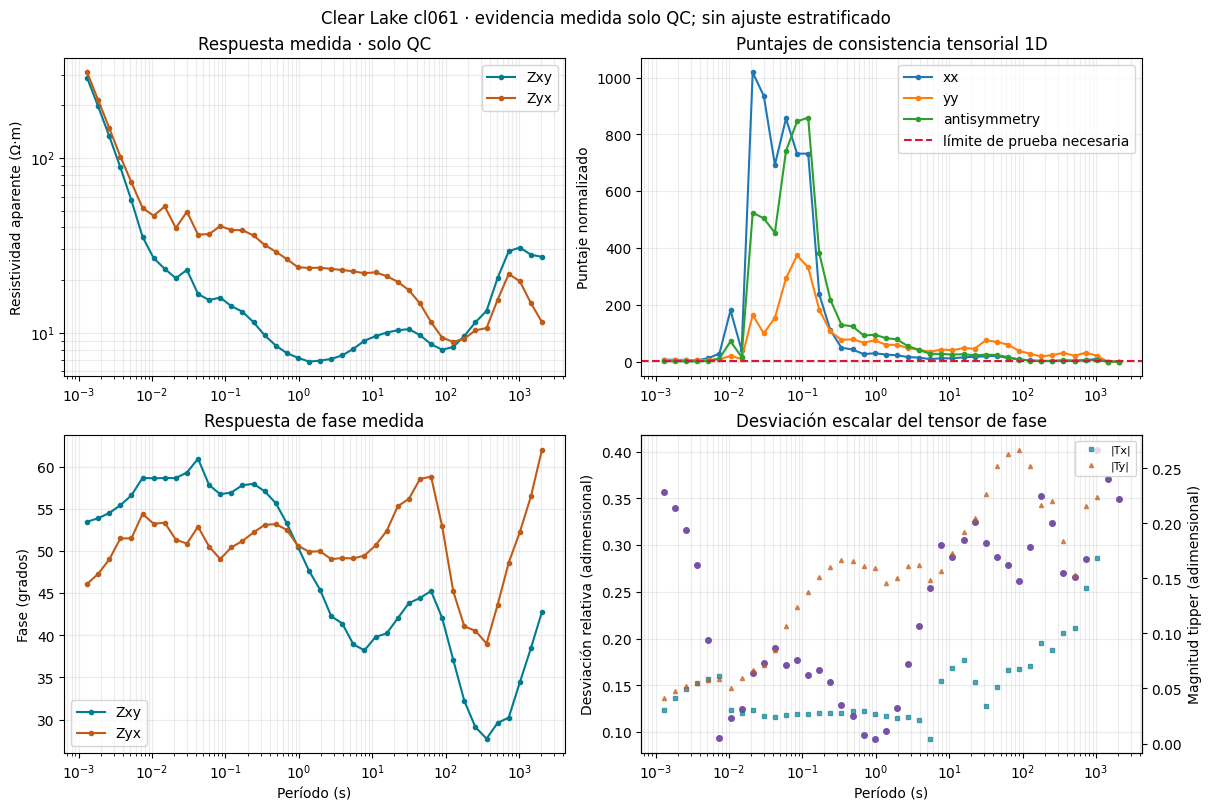

Frecuencias faltantes del tipper (Hz): [0.0004882812, 0.0006915263]
La convención de varianza del tipper no está interpretada; no se muestran barras de incertidumbre.


In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for name,color in (("xy","#007c91"),("yx","#bf5b17")):
 q=case["observed"][name]; ax[0,0].loglog(period,q["apparent"],".-",label="Z"+name,color=color); ax[1,0].semilogx(period,q["phase"],".-",label="Z"+name,color=color)
ax[0,0].set_ylabel("Resistividad aparente (Ω·m)"); ax[1,0].set_ylabel("Fase (grados)"); ax[1,0].set_xlabel("Período (s)")
for a in (ax[0,0],ax[1,0]): a.grid(True,which="both",alpha=.25); a.legend()
ax[0,0].set_title("Respuesta medida · solo QC")
for key,score in gate["per_period_normalized"].items(): ax[0,1].semilogx(period,score,".-",label=key)
ax[0,1].axhline(gate["threshold"],color="crimson",ls="--",label="límite de prueba necesaria"); ax[0,1].set_title("Puntajes de consistencia tensorial 1D"); ax[0,1].set_ylabel("Puntaje normalizado"); ax[0,1].legend(); ax[0,1].grid(True,which="both",alpha=.25)
pt=phase_qc["per_period"]; pt_period=np.asarray([period[row["source_index"]] for row in pt]); pt_depart=np.asarray([row["scalar_departure"] for row in pt])
ax[1,0].set_title("Respuesta de fase medida"); ax[1,1].semilogx(pt_period,pt_depart,"o",ms=4,color="#7651a8"); ax[1,1].set_title("Desviación escalar del tensor de fase"); ax[1,1].set_ylabel("Desviación relativa (adimensional)"); ax[1,1].set_xlabel("Período (s)"); ax[1,1].grid(True,which="both",alpha=.25)
# La varianza del tipper no se interpreta: graficar magnitud bruta y conservar faltantes como NaN.
tf=np.asarray(tip["components"]["X"]["real"],dtype=float)+1j*np.asarray(tip["components"]["X"]["imag"],dtype=float); ty=np.asarray(tip["components"]["Y"]["real"],dtype=float)+1j*np.asarray(tip["components"]["Y"]["imag"],dtype=float)
ax2=ax[1,1].twinx(); ax2.semilogx(period,np.abs(tf),"s",ms=3,color="#007c91",alpha=.65,label="|Tx|"); ax2.semilogx(period,np.abs(ty),"^",ms=3,color="#bf5b17",alpha=.65,label="|Ty|"); ax2.set_ylabel("Magnitud tipper (adimensional)")
h,l=ax[1,1].get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels(); ax2.legend(h+h2,l+l2,fontsize=8,loc="best")
fig.suptitle("Clear Lake cl061 · evidencia medida solo QC; sin ajuste estratificado"); plt.show()
print("Frecuencias faltantes del tipper (Hz):",tip["missing_frequency_hz"])
print("La convención de varianza del tipper no está interpretada; no se muestran barras de incertidumbre.")

## Resultados

El conjunto permanece solo-QC porque falla el filtro de elegibilidad 1D; sus diagnósticos de tensor y tipper no son una inversión estratificada. Los períodos faltantes del tipper siguen faltantes.

## Resumen

Use la decisión QC solo para determinar si una inversa estratificada 1D es elegible. `cl061` falla la prueba necesaria y permanece excluido del ajuste 1D.

## Referencias

- [MTpy v2](https://github.com/MTgeophysics/mtpy-v2)
- [Datos magnetotelúricos USGS de Clear Lake](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)
